# Breast tumour vs normal tissue: enrichment and sample structure

Downstream of the edgeR differential expression (`DGEA_analysis-edgeR.Rmd`),
which compares TCGA-BRCA primary tumours with GTEx normal breast tissue.

**Produces** Figure 4 and Supplementary Figure S1 of the article, and
Supplementary Tables S12-S13 (`../../results/tables/ora_tissue/`).

In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import umap

sys.path.insert(0, "..")
from common import enrich

TABLES = "../../results/tables/ora_tissue"
FIGURES = "../../figures"
DATA = "../../data/external"

P_CUTOFF = 0.05   # raw p-value filter applied to the edgeR table
Z_CUTOFF = 2      # z-score on logFC, for calling a gene up- or down-regulated
TOP_N = 25        # pathways shown per panel

## 1. Deregulated genes

The z-score is computed on the logFC across genes, so `|z| > 2` selects the
genes whose fold change stands out from the overall distribution — the same
threshold used on the L1000 signatures in `analyses/03`, which is what makes
the two sides comparable in `analyses/05`.

In [2]:
tissue = pd.read_csv(f"{DATA}/DGEA_TCGA_GTEX/DGEA_edgeR_QLF_all.csv", index_col=0)
tissue = tissue[tissue["PValue"] < P_CUTOFF]

genes_up = tissue.index[tissue["z_score"] > Z_CUTOFF].tolist()
genes_down = tissue.index[tissue["z_score"] < -Z_CUTOFF].tolist()
print(f"{len(tissue)} genes with p < {P_CUTOFF} | "
      f"{len(genes_up)} up, {len(genes_down)} down at |z| > {Z_CUTOFF}")

14701 genes with p < 0.05 | 510 up, 441 down at |z| > 2


## 2. KEGG over-representation (Tables S12-S13)

In [3]:
enrich_up = enrich(genes_up, "KEGG_2021_Human")
enrich_down = enrich(genes_down, "KEGG_2021_Human")

for name, res in (("up", enrich_up), ("down", enrich_down)):
    table = res.res2d
    table = table[table["Adjusted P-value"] < 0.05]
    table.to_csv(f"{TABLES}/ORA_Kegg_{name}_tissue.csv")
    print(f"{name:4s}: {len(table)} significant KEGG pathways")

up  : 20 significant KEGG pathways
down: 34 significant KEGG pathways


## 3. Figure 4

Panel A: pathways enriched among up-regulated genes. Panel B: the same for
down-regulated genes.

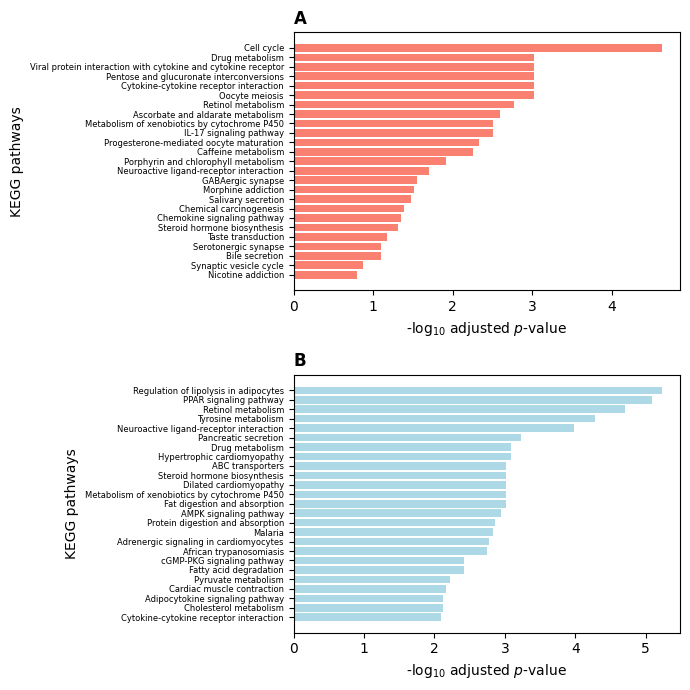

In [4]:
def panel(ax, res, color, label):
    table = res.res2d.assign(
        logAP=-np.log10(res.res2d["Adjusted P-value"].values)
    )[["Term", "logAP"]].head(TOP_N)
    table = table[table["logAP"] > 0.05].sort_values("logAP")

    ax.barh([t.split("(")[0] for t in table["Term"]], table["logAP"], color=color)
    ax.set_xlabel("-log$_{10}$ adjusted $p$-value")
    ax.set_ylabel("KEGG pathways")
    ax.tick_params(axis="y", labelsize=6)
    ax.set_title(label, loc="left", fontweight="bold")


fig, axes = plt.subplots(2, 1, figsize=(7, 7))
panel(axes[0], enrich_up, "salmon", "A")
panel(axes[1], enrich_down, "lightblue", "B")
plt.tight_layout()
for ext in ("png", "pdf"):
    fig.savefig(f"{FIGURES}/Figure-4_ORA_Kegg_Tissue_combined.{ext}",
                dpi=500, bbox_inches="tight")
plt.show()

## 4. Supplementary Figure S1 — sample structure by pathological stage

A UMAP of all tumour and normal expression profiles, coloured by pathological
stage. The point is descriptive: it shows that the tumour / normal separation
dominates, while stages do not form separate groups — which is why the rest of
the study pools stages instead of modelling them.

⚠️ UMAP is stochastic and its global distances are not meaningful; the layout
will differ between runs and should not be read as a quantitative result.

In [5]:
# Back-transformed expected counts, tumour and normal samples as columns.
expression = pd.read_csv(
    f"{DATA}/TCGA/DGEA_Protocol/BT_ExpressionProfiles_GTEX-TCGA.csv", index_col=0
).T

# Pathological stage per TCGA sample; GTEx samples are the normal reference.
clinical = pd.read_csv(
    f"{DATA}/TCGA/DGEA_Protocol/TCGA.BRCA.sampleMAP_BRCA_clinicalMatrix.tsv", sep="\t"
)
clinical["sampleID"] = clinical["sampleID"].str.replace("-", ".")
stage_of_sample = dict(zip(clinical["sampleID"], clinical["pathologic_stage"]))


def coarse_stage(sample_id):
    """Collapse sub-stages (IA, IB, IIIC ...) into the four main stages."""
    if sample_id.startswith("GTEX"):
        return "Healthy"
    stage = stage_of_sample.get(sample_id)
    if not isinstance(stage, str):
        return "Unclassifiable"
    for roman in ("IV", "III", "II", "I"):
        if stage.startswith(f"Stage {roman}"):
            return f"Stage {roman}"
    return "Unclassifiable"


stages = [coarse_stage(s) for s in expression.index]
print(pd.Series(stages).value_counts().to_string())

Stage II          618
Stage III         249
Stage I           182
Healthy           178
Unclassifiable     23
Stage IV           20


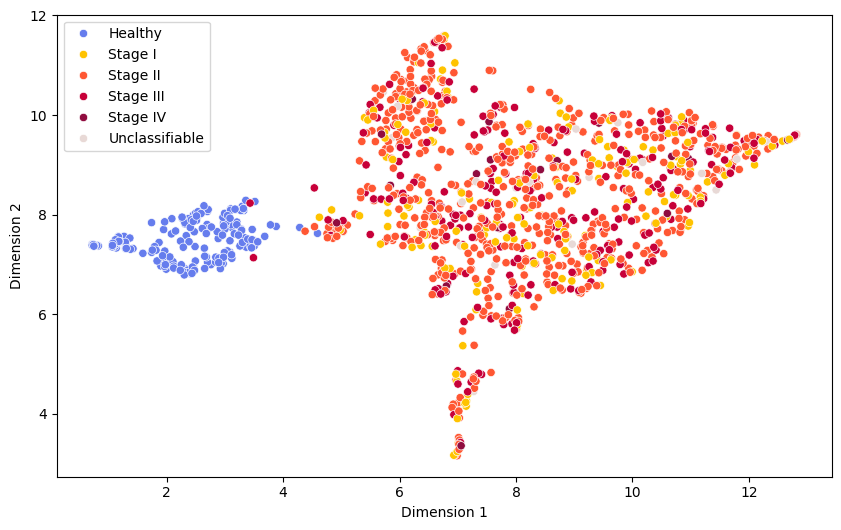

In [6]:
embedding = umap.UMAP(random_state=0).fit_transform(expression)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=embedding[:, 0], y=embedding[:, 1], hue=stages,
    hue_order=["Healthy", "Stage I", "Stage II", "Stage III", "Stage IV",
               "Unclassifiable"],
    palette=["#667ded", "#FFC300", "#FF5733", "#C70039", "#900C3F", "#e8d9d6"],
)
plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")
for ext in ("png", "pdf"):
    plt.savefig(
        f"{FIGURES}/Supplementary_Figure-S1_UMAP_BreastCancer_TumoralTissue.{ext}",
        dpi=500, bbox_inches="tight",
    )
plt.show()